Note: you may need to restart the kernel to use updated packages.
Lycorma delicatula: 5392 observations
Ailanthus altissima: 645 observations


,queried_species,decimalLongitude,decimalLatitude,geometry
0,Lycorma delicatula,-77.165722,38.869136,POINT (1608346.159 1920142.24)
1,Lycorma delicatula,-77.243430,39.806403,POINT (1581199.176 2021832.771)
2,Lycorma delicatula,-76.151918,39.617536,POINT (1676298.848 2019810.301)
3,Lycorma delicatula,-76.932797,38.932323,POINT (1626559.301 1931048.498)
4,Lycorma delicatula,-76.870619,39.001428,POINT (1630243.19 1939703.528)


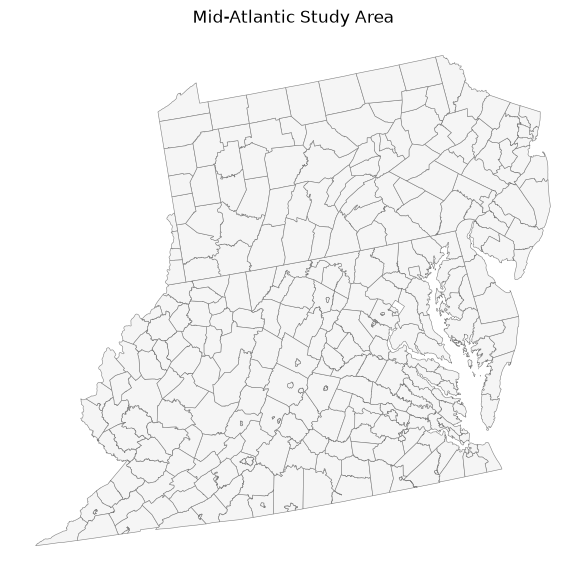

,queried_species,decimalLongitude,decimalLatitude,geometry,GEOID
0,Lycorma delicatula,-77.165722,38.869136,POINT (1608346.159 1920142.24),51059
1,Lycorma delicatula,-77.243430,39.806403,POINT (1581199.176 2021832.771),42001
2,Lycorma delicatula,-76.151918,39.617536,POINT (1676298.848 2019810.301),24025
3,Lycorma delicatula,-76.932797,38.932323,POINT (1626559.301 1931048.498),24033
4,Lycorma delicatula,-76.870619,39.001428,POINT (1630243.19 1939703.528),24033


,NAME,GEOID,Lycorma delicatula,Ailanthus altissima,total
3,Sussex,10005,12.0,1.0,13.0
16,New Castle,10003,17.0,3.0,20.0
60,Baltimore,24005,56.0,9.0,65.0
61,Dorchester,24019,2.0,0.0,2.0
62,Charles,24017,4.0,3.0,7.0


c:\Users\Jakcr\OneDrive\Documents\Dev (PC)\geog592-kirjo\.venv\Lib\site-packages\geopandas\plotting.py:1036: UserWarning: Numba not installed. Using slow pure python version.
  binning = mapclassify.classify(values[mask], scheme, **classification_kwds)


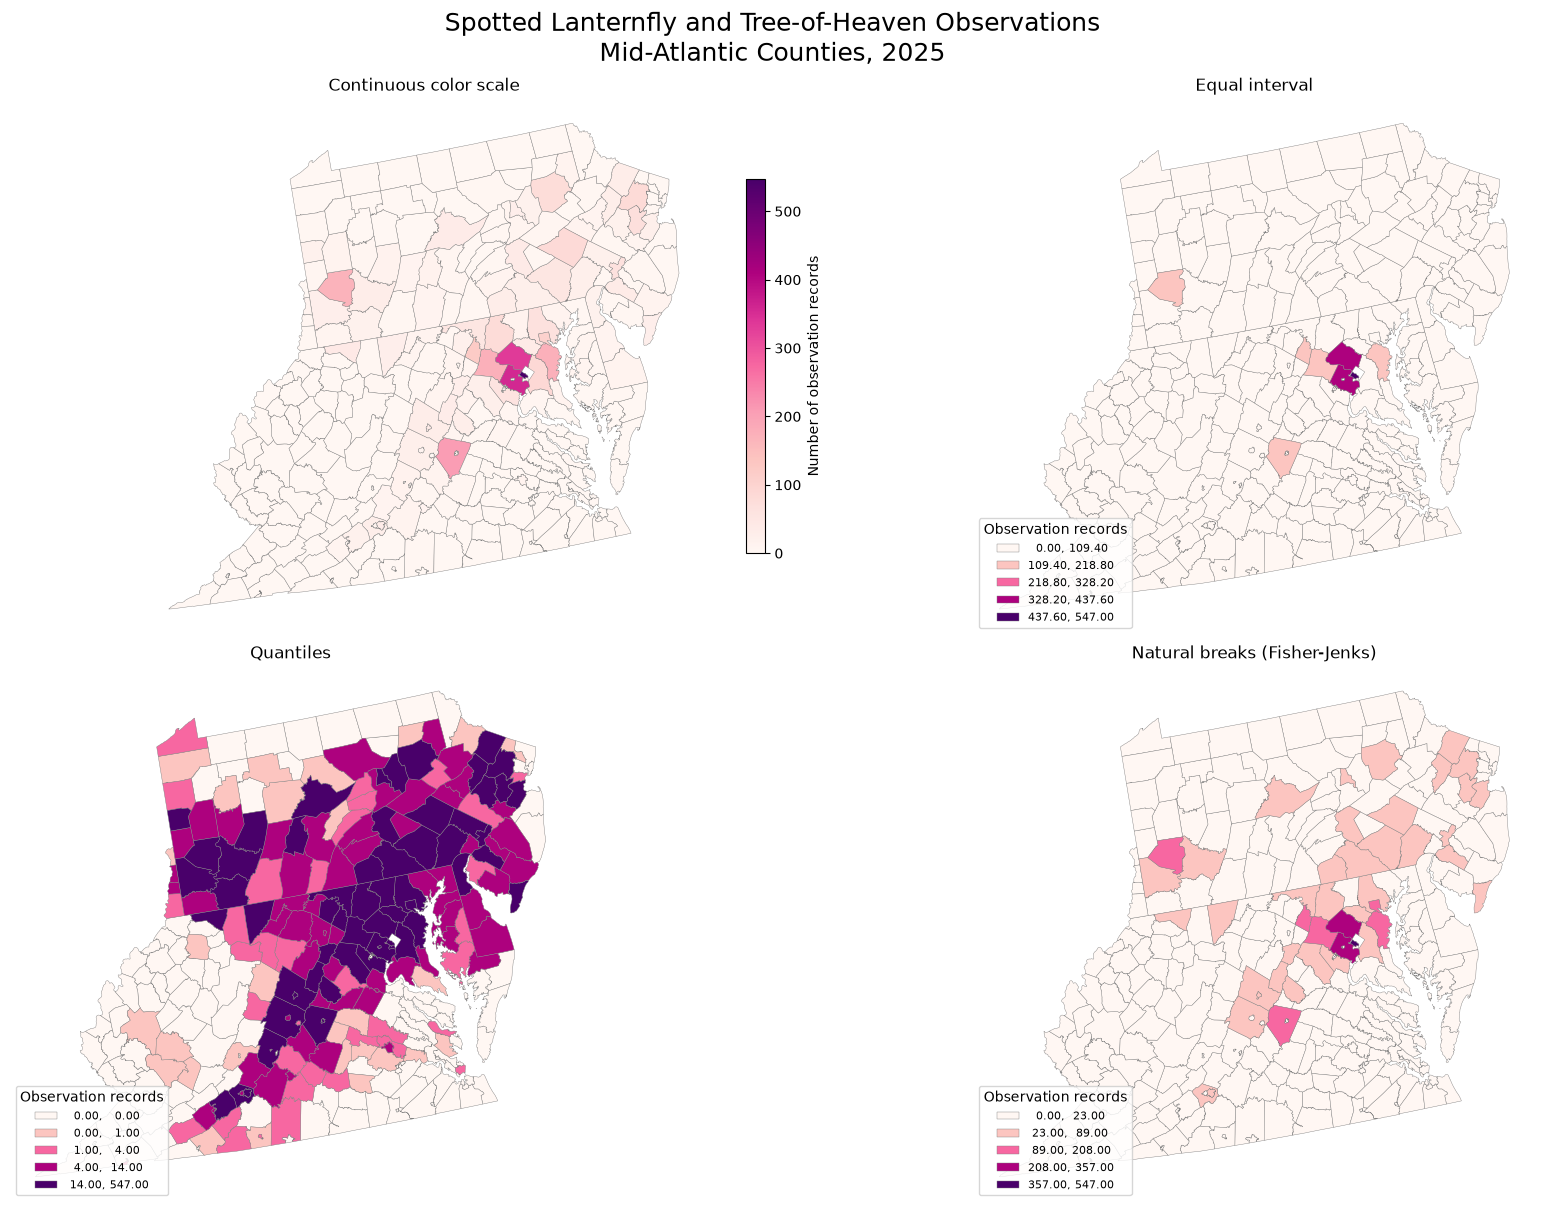

Lycorma delicatula positive-count median: 9.0
Ailanthus altissima positive-count median: 2.0


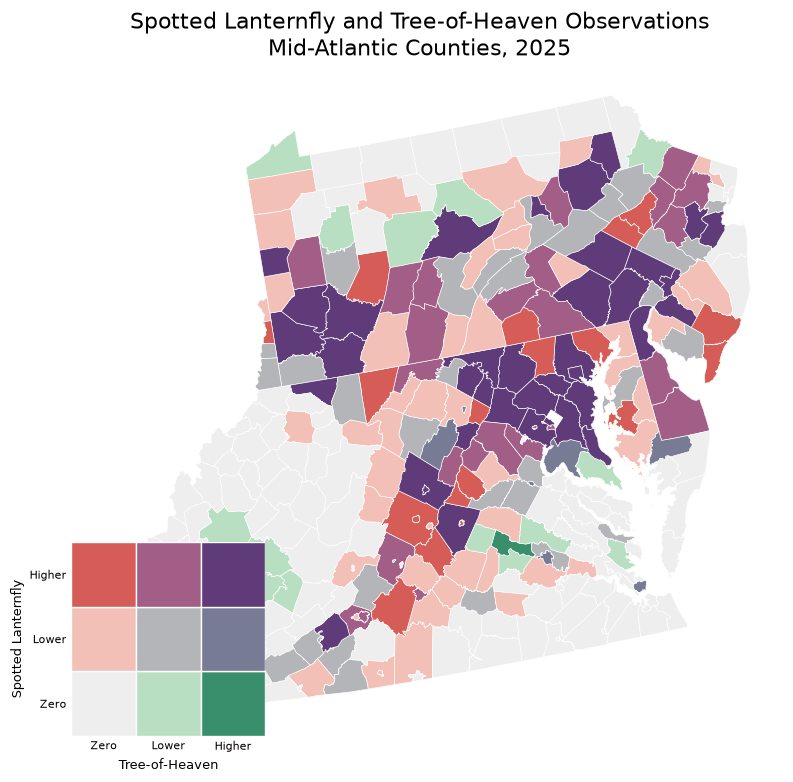

Finished! Files saved:
week09_four_choropleths.png
week09_bivariate_map.png
week09_description.txt


In [2]:
# Install packages
%pip install -q geopandas mapclassify requests

# Import libraries
import time
import requests
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle



# Download species observations from GBIF


species = ["Lycorma delicatula", "Ailanthus altissima"]

# Spotted lanternfly and tree-of-heaven
year = 2025
months = "8,9" 

api = "https://api.gbif.org/v1"
records = []

for name in species:

    response = requests.get(
        f"{api}/species/match",
        params={"name": name, "strict": "true"},
        timeout=60
    )
    response.raise_for_status()

    match = response.json()

    if match.get("matchType") != "EXACT" or match.get("rank") != "SPECIES":
        raise ValueError(f"Check species name: {name}")

    taxon_key = match.get("acceptedUsageKey") or match["usageKey"]

    parameters = {
        "taxonKey": taxon_key,
        "country": "US",
        "year": year,
        "month": months,
        "decimalLongitude": "-84,-74.4",
        "decimalLatitude": "36,42.6",
        "basisOfRecord": "HUMAN_OBSERVATION",
        "occurrenceStatus": "PRESENT",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "limit": 300,
        "offset": 0
    }

    species_records = []

    while True:

        response = requests.get(
            f"{api}/occurrence/search",
            params=parameters,
            timeout=60
        )
        response.raise_for_status()

        page = response.json()

        if page["count"] > 9000:
            raise ValueError(
                f"{name} has too many records. "
                "Try changing months to '8'."
            )

        for record in page["results"]:
            record["queried_species"] = name

        species_records.extend(page["results"])

        if page.get("endOfRecords") or not page["results"]:
            break

        parameters["offset"] += len(page["results"])
        time.sleep(0.2)

    records.extend(species_records)

    print(f"{name}: {len(species_records)} observations")



# Convert observations into a GeoDataFrame


observations = pd.DataFrame(records)

if observations.empty:
    raise ValueError("No observations found. Try another year or month.")

observations = observations[
    ["queried_species", "decimalLongitude", "decimalLatitude"]
].copy()

observations["decimalLongitude"] = pd.to_numeric(
    observations["decimalLongitude"], errors="coerce"
)
observations["decimalLatitude"] = pd.to_numeric(
    observations["decimalLatitude"], errors="coerce"
)

observations = observations.dropna(
    subset=["decimalLongitude", "decimalLatitude"]
)

species_points = gpd.GeoDataFrame(
    observations,
    geometry=gpd.points_from_xy(
        observations["decimalLongitude"],
        observations["decimalLatitude"]
    ),
    crs="EPSG:4326"
)

species_points = species_points.to_crs(epsg=5070)

display(species_points.head())



# Download county boundaries


url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/"
url_county = "cb_2024_us_county_500k.zip"

counties = gpd.read_file(url_0 + url_county)

# Pennsylvania, New Jersey, Delaware,
# Maryland, Virginia, and West Virginia

state_codes = ["42", "34", "10", "24", "51", "54"]

mid_atlantic = counties.loc[
    counties["STATEFP"].isin(state_codes)
].copy()

mid_atlantic = mid_atlantic.to_crs(epsg=5070)

fig, ax = plt.subplots(figsize=(10, 7))

mid_atlantic.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.4
)

ax.set_title("Mid-Atlantic Study Area")
ax.set_axis_off()

plt.show()



# Spatial join: observations within counties


points_by_county = gpd.sjoin(
    species_points,
    mid_atlantic[["GEOID", "geometry"]],
    how="inner",
    predicate="within"
).drop(columns="index_right")

display(points_by_county.head())


# Count observations by species and county


counts = (
    points_by_county
    .groupby(["GEOID", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=species, fill_value=0)
)

county_map = mid_atlantic.merge(
    counts,
    left_on="GEOID",
    right_index=True,
    how="left"
)

county_map[species] = county_map[species].fillna(0)

# Combined total of the two species
county_map["total"] = county_map[species].sum(axis=1)

display(
    county_map[
        ["NAME", "GEOID", "Lycorma delicatula",
         "Ailanthus altissima", "total"]
    ].head()
)



# Four choropleth classification maps


fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12),
    layout="constrained"
)

schemes = [
    ("Continuous color scale", None),
    ("Equal interval", "equalinterval"),
    ("Quantiles", "quantiles"),
    ("Natural breaks (Fisher-Jenks)", "fisherjenks")
]

if county_map["total"].nunique() < 2:
    raise ValueError("Not enough variation in county observations to classify.")

for ax, (title, scheme) in zip(axes.flat, schemes):

    options = {
        "column": "total",
        "cmap": "RdPu",
        "edgecolor": "gray",
        "linewidth": 0.3,
        "legend": True,
        "ax": ax
    }

    if scheme is None:
        options["legend_kwds"] = {
            "label": "Number of observation records",
            "shrink": 0.7
        }

    else:
        options["scheme"] = scheme
        options["k"] = min(5, county_map["total"].nunique())
        options["legend_kwds"] = {
            "title": "Observation records",
            "fontsize": 8,
            "loc": "lower left"
        }

    county_map.plot(**options)

    ax.set_title(title)
    ax.set_axis_off()

fig.suptitle(
    "Spotted Lanternfly and Tree-of-Heaven Observations\n"
    "Mid-Atlantic Counties, 2025",
    fontsize=18
)

fig.savefig(
    "week09_four_choropleths.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



# Bivariate map


# Classify each species
# 0 = no observations
# 1 = lower positive observation count
# 2 = higher positive observation count

for name in species:

    values = county_map[name]
    positive = values.loc[values > 0]

    median = positive.median() if len(positive) else 0

    county_map[name + "_class"] = np.select(
        [values == 0, values <= median],
        [0, 1],
        default=2
    )

    print(name, "positive-count median:", median)


# Rows = spotted lanternfly counts
# Columns = tree-of-heaven counts

palette = np.array([
    ["#eeeeee", "#b8dfc2", "#398f6b"],
    ["#f3c0b7", "#b4b5b9", "#777b94"],
    ["#d65d57", "#a25e86", "#603b79"]
])


county_map["bivar_color"] = [
    palette[lanternfly, tree]
    for lanternfly, tree in zip(
        county_map["Lycorma delicatula_class"],
        county_map["Ailanthus altissima_class"]
    )
]


# Create bivariate map

fig, ax = plt.subplots(figsize=(14, 9))

county_map.plot(
    color=county_map["bivar_color"],
    edgecolor="white",
    linewidth=0.45,
    ax=ax
)

ax.set_title(
    "Spotted Lanternfly and Tree-of-Heaven Observations\n"
    "Mid-Atlantic Counties, 2025",
    fontsize=16
)

ax.set_axis_off()



# Add bivariate legend

legend_ax = ax.inset_axes([0.02, 0.03, 0.27, 0.28])

for lanternfly in range(3):
    for tree in range(3):

        legend_ax.add_patch(
            Rectangle(
                (tree, lanternfly),
                1,
                1,
                facecolor=palette[lanternfly, tree],
                edgecolor="white"
            )
        )

legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_aspect("equal")

legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_yticks([0.5, 1.5, 2.5])

legend_ax.set_xticklabels(
    ["Zero", "Lower", "Higher"],
    fontsize=8
)

legend_ax.set_yticklabels(
    ["Zero", "Lower", "Higher"],
    fontsize=8
)

legend_ax.set_xlabel(
    "Tree-of-Heaven",
    fontsize=9
)

legend_ax.set_ylabel(
    "Spotted Lanternfly",
    fontsize=9
)

legend_ax.tick_params(length=0)

for spine in legend_ax.spines.values():
    spine.set_visible(False)


# Save bivariate map

fig.savefig(
    "week09_bivariate_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("Finished! Files saved:")
print("week09_four_choropleths.png")
print("week09_bivariate_map.png")
print("week09_description.txt")

#AI USE

I used AI to help with the mapping, as I was very confused about that (I wasn't in class yesterday or today I am with my Grandma)